# SA-CCR on the five official netting sets

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 02 of this topic (collateral and the margin period of risk)
- **Reading time:** about 55 minutes

**Question:** What exposure at default does SA-CCR assign to the five netting sets the Basel framework works through, and how much do the offset between maturity buckets, the multiplier and a margin agreement take off the supervisory add-on?

## Objectives

By the end of this notebook you can:

- state the SA-CCR formula $EAD = 1.4\,(RC + PFE)$ and each piece of it: replacement cost, multiplier, aggregate add-on;
- compute the supervisory duration, the supervisory delta of a linear trade and of an option, and the maturity factor, margined or not;
- compute the interest-rate add-on with its three maturity buckets and offset, the credit add-on with its systematic and idiosyncratic terms, and the commodity add-on;
- reproduce the five examples of the Basel framework (CRE99) from their trades, and compare each intermediate with the printed, rounded value;
- say what the engine does not implement of SA-CCR.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ccr import collateral as col
from riskvalidation.regulatory import sa_ccr

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

The data are the regulatory calculators document, `data/derived/regulatory/calculators.json`, schema `contraste.regulatory/v1`. It is not a market dataset: its truth status is `published-answer`. It holds the trades and inputs of the five worked examples of the Basel framework chapter CRE99 (netting sets 1 to 5, transcribed from the BIS page; amounts in USD thousands), the answers the framework prints (rounded), and the answers the engine recomputed when the document was baked, with the paragraph and the in-force date of each rule (2023-01-01).

- **File read:** `data/derived/regulatory/calculators.json`, keys `official_examples`, `parameter_tables` and `provenance`.
- **What is transcribed and what is recomputed:** every input has `basis: transcribed` and every output `basis: recomputed`; the document's `published` list holds what the BIS prints, with its rounding.
- **How we compare:** this notebook computes each output from the trades with the engine's SA-CCR functions and, in the last step, compares it with the value the BIS prints (after the printed rounding).

The next cell loads the document and lists the examples.

In [2]:
# Load the regulatory calculators document (three folders below the repository root) and list its examples
ROOT = Path("../../..").resolve()
doc = json.loads((ROOT / "data" / "derived" / "regulatory" / "calculators.json").read_text(encoding="utf-8"))

print("document:", doc["document_id"], "| truth status:", doc["provenance"]["truth_status"])
examples = {e["id"]: e for e in doc["official_examples"]}
for ident, e in examples.items():
    span = e["paragraph_range"].replace(" to ", " to ").replace(" and ", " and ")
    print(f"{ident:28s} {e['calculator']:8s} {len(e['trades']):2d} trades | {span:22s}")

document: regulatory-calculators-1.0.1 | truth status: published-answer
cre99-netting-set-1          sa-ccr    3 trades | CRE52.10 to CRE52.57  
cre99-netting-set-2          sa-ccr    3 trades | CRE52.61 to CRE52.65  
cre99-netting-set-3          sa-ccr    3 trades | CRE52.70 to CRE52.71  
cre99-netting-set-4          sa-ccr    6 trades | CRE52.24 to CRE52.25  
cre99-netting-set-5          sa-ccr    6 trades | CRE52.18 to CRE52.52  
rbc20-13-output-floor        output-floor  0 trades | RBC20.4 and RBC20.11 to RBC20.13
rbc20-13-output-floor-capped output-floor  0 trades | RBC90.1 to RBC90.2    


## Method

### Step 1: the formula and the supervisory parameters

SA-CCR (CRE52, in force 2023-01-01) measures the exposure at default of a netting set as

$$EAD = \alpha\,(RC + PFE), \qquad \alpha = 1.4, \qquad PFE = \text{multiplier} \times \text{AddOn}^{aggregate}$$

where RC is the replacement cost (the loss today if the counterparty defaulted, net of collateral), the aggregate add-on is the sum of the add-ons of the five asset classes, and the multiplier lets over-collateralisation reduce the PFE:

$$\text{multiplier} = \min\Big(1,\ \text{Floor} + (1 - \text{Floor})\,e^{(V - C)/(2(1 - \text{Floor})\,\text{AddOn}^{aggregate})}\Big), \qquad \text{Floor} = 5\%$$

The supervisory factor, correlation and option volatility of each asset class are the numbers of the table of CRE52.72. The engine keeps them as data with their paragraph, table and in-force date, in `RegulatoryParameter` objects. The next cell reads some of them and counts the rows of the table.

In [3]:
# Read some supervisory parameters with their paragraph, and count the rows of the table
OTHER = "commodity-oil-gas-metals-agricultural-other"
wanted = (
    ("interest-rate", "supervisory_factor"), ("fx", "supervisory_factor"),
    ("credit-single-name-AA", "supervisory_factor"), ("credit-single-name-BBB", "supervisory_factor"),
    ("credit-index-IG", "correlation"), (OTHER, "supervisory_factor"), (OTHER, "correlation"),
)
for key, name in wanted:
    p = sa_ccr.supervisory_parameter(key, name)
    print(f"{key:46s} {name:18s} {p.value:7.4f} | {p.paragraph} | {p.table} | {p.in_force}")

table = next(t for t in doc["parameter_tables"] if t["id"] == "cre52-72-table-2")
print("rows of CRE52.72 Table 2 in the document:", len(table["rows"]))
print("alpha:", sa_ccr.ALPHA, "| multiplier floor:", sa_ccr.MULTIPLIER_FLOOR, "| in force:", sa_ccr.CRE52_IN_FORCE)

interest-rate                                  supervisory_factor  0.0050 | CRE52.72 | CRE52.72 Table 2 | 2023-01-01
fx                                             supervisory_factor  0.0400 | CRE52.72 | CRE52.72 Table 2 | 2023-01-01
credit-single-name-AA                          supervisory_factor  0.0038 | CRE52.72 | CRE52.72 Table 2 | 2023-01-01
credit-single-name-BBB                         supervisory_factor  0.0054 | CRE52.72 | CRE52.72 Table 2 | 2023-01-01
credit-index-IG                                correlation         0.8000 | CRE52.72 | CRE52.72 Table 2 | 2023-01-01
commodity-oil-gas-metals-agricultural-other    supervisory_factor  0.1800 | CRE52.72 | CRE52.72 Table 2 | 2023-01-01
commodity-oil-gas-metals-agricultural-other    correlation         0.4000 | CRE52.72 | CRE52.72 Table 2 | 2023-01-01
rows of CRE52.72 Table 2 in the document: 43
alpha: 1.4 | multiplier floor: 0.05 | in force: 2023-01-01


### Step 2: duration, delta and maturity factor

Three small functions turn a trade into its effective notional (CRE52.34 to CRE52.52):

- the **supervisory duration** of a trade that starts at $S$ and ends at $E$ (years) is $SD = (e^{-0.05 S} - e^{-0.05 E})/0.05$; it multiplies the notional of interest-rate and credit trades;
- the **supervisory delta** is $\pm 1$ for a linear trade (positive for the payer of fixed, the protection buyer and the long position), and for an option the normal-distribution value $\pm\Phi(\pm d)$ with $d = (\ln(P/K) + \tfrac12 \sigma^2 T)/(\sigma\sqrt{T})$, the sign and the side of $\Phi$ set by buying or selling a call or a put;
- the **maturity factor** is $MF = \sqrt{\min(M, 1)}$ for an unmargined trade and $MF = 1.5\sqrt{MPoR/250}$ for a margined netting set, with the MPoR in business days.

The next cell evaluates them on the trades of the first example and on a few special values.

In [4]:
# Duration, delta and maturity factor on the trades of netting set 1, the margined factor and an option delta
ns1 = examples["cre99-netting-set-1"]
terms1 = [{v["name"]: v["value"] for v in tr["terms"]} for tr in ns1["trades"]]
print(f"{'trade':8s}{'start':>7s}{'end':>6s}{'SD':>9s}{'MF':>7s}  bucket")
for tr, t in zip(ns1["trades"], terms1):
    sd = sa_ccr.supervisory_duration(t["start_years"], t["end_years"])
    mf = sa_ccr.maturity_factor(t["end_years"])
    bucket = sa_ccr.maturity_bucket(t["end_years"])
    print(f"{tr['trade_id']:8s}{t['start_years']:7.0f}{t['end_years']:6.0f}{sd:9.4f}{mf:7.3f}  {bucket}")

print("margined maturity factor, MPoR 14 and 10 days:",
      round(sa_ccr.maturity_factor(5.0, 14), 6), round(sa_ccr.maturity_factor(5.0, 10), 6))
swaption = terms1[2]
opt_keys = ("option_price", "option_strike", "option_volatility", "option_expiry_years")
opt = [swaption[k] for k in opt_keys]
delta_put = sa_ccr.supervisory_delta_option(*opt, False, True)
delta_sold = sa_ccr.supervisory_delta_option(*opt, False, False)
print("swaption:", swaption["option_type"], dict(zip(opt_keys, opt)))
print("delta of the bought put:", round(delta_put, 6), "| sold put:", round(delta_sold, 6))

trade     start   end       SD     MF  bucket
T1            0    10   7.8694  1.000  B3
T2            0     4   3.6254  1.000  B2
T3            1    11   7.4856  1.000  B3
margined maturity factor, MPoR 14 and 10 days: 0.354965 0.3
swaption: bought-put {'option_price': 0.06, 'option_strike': 0.05, 'option_volatility': 0.5, 'option_expiry_years': 1}
delta of the bought put: -0.269395 | sold put: 0.269395


### Step 3: the interest-rate add-on (netting set 1)

Each interest-rate trade has an effective notional $\delta \times N \times SD \times MF$. Trades in one currency form a hedging set. Inside it they fall in three maturity buckets (B1 below one year, B2 from one to five, B3 above five years, by the end date) and the buckets offset each other by the formula of CRE52.57:

$$EN = \sqrt{D_1^2 + D_2^2 + D_3^2 + 1.4\,D_1 D_2 + 1.4\,D_2 D_3 + 0.6\,D_1 D_3}$$

with $D_k$ the sum of the effective notionals in bucket $k$; the add-on of the hedging set is $0.5\% \times EN$. The engine's `ir_addon` returns the trade rows, the hedging-set rows and the total, each with its intermediates. The swaption of netting set 1 is in EUR, so it forms a second hedging set. The next cell builds the trades and prints every intermediate.

In [5]:
# The interest-rate trades of netting set 1 with their supervisory deltas, and every intermediate of ir_addon
LINEAR_DELTA = {"pay-fixed-receive-floating": 1.0, "pay-floating-receive-fixed": -1.0,
                "protection-buyer": 1.0, "protection-seller": -1.0, "long": 1.0, "short": -1.0}
ir_trades = []
for t in terms1:
    delta = delta_put if t.get("option_type", "none") != "none" else LINEAR_DELTA[t["position"]]
    ir_trades.append(sa_ccr.IrTrade(t["currency"], t["start_years"], t["end_years"], t["notional"], delta))
ir = sa_ccr.ir_addon(ir_trades)
no_offset = sa_ccr.ir_addon(ir_trades, offset=False).addon

print(f"{'set':5s}{'delta':>8s}{'N*SD':>12s}{'MF':>7s}{'bucket':>7s}{'eff. notional':>16s}")
for row in ir.trades:
    print(f"{row.hedging_set:5s}{row.delta:8.4f}{row.adjusted_notional:12.2f}{row.maturity_factor:7.3f}"
          f"{row.bucket:>7s}{row.effective_notional:16.4f}")
for h in ir.hedging_sets:
    print(f"hedging set {h.hedging_set}: D1 = {h.d_b1:.2f}, D2 = {h.d_b2:.2f}, D3 = {h.d_b3:.2f}"
          f" | EN = {h.effective_notional:.4f} | add-on {h.addon:.4f}")
print("interest-rate add-on:", round(ir.addon, 6))
print("without the offset between buckets:", round(no_offset, 4),
      "| the offset removes", f"{1 - ir.addon / no_offset:.1%}")

set     delta        N*SD     MF bucket   eff. notional
USD    1.0000    78693.87  1.000     B3      78693.8681
USD   -1.0000    36253.85  1.000     B2     -36253.8494
EUR   -0.2694    37427.96  1.000     B3     -10082.9138
hedging set USD: D1 = 0.00, D2 = -36253.85, D3 = 78693.87 | EN = 59269.9635 | add-on 296.3498
hedging set EUR: D1 = 0.00, D2 = 0.00, D3 = -10082.91 | EN = 10082.9138 | add-on 50.4146
interest-rate add-on: 346.764386
without the offset between buckets: 625.1532 | the offset removes 44.5%


The next cell draws the effective notional of each interest-rate trade, with its currency and bucket, and the add-on with and without the offset between buckets.

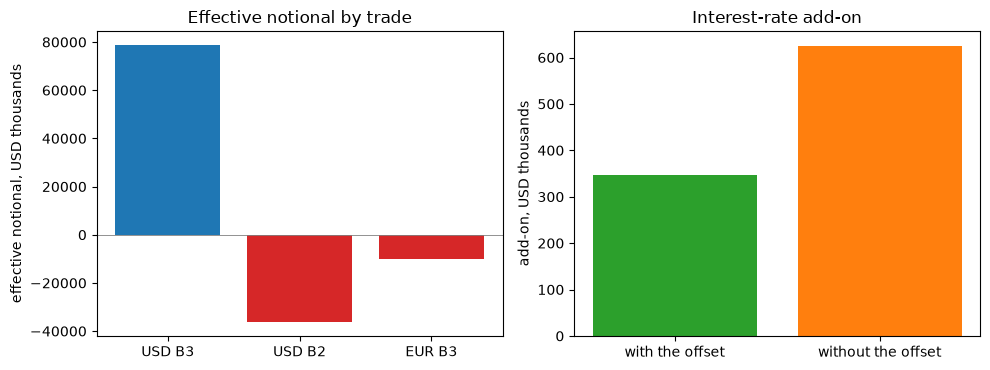

In [6]:
# Draw the effective notional of each interest-rate trade (left) and the add-on with and without the offset (right)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
labels = [f"{row.hedging_set} {row.bucket}" for row in ir.trades]
effective = [row.effective_notional for row in ir.trades]
left.bar(labels, effective, color=["tab:blue" if v > 0 else "tab:red" for v in effective])
left.axhline(0, color="grey", lw=0.6)
left.set_ylabel("effective notional, USD thousands")
left.set_title("Effective notional by trade")
right.bar(["with the offset", "without the offset"], [ir.addon, no_offset],
          color=["tab:green", "tab:orange"])
right.set_ylabel("add-on, USD thousands")
right.set_title("Interest-rate add-on")
fig.tight_layout()
plt.show()

On the left, the 10-year payer and the EUR swaption sit in bucket B3 with opposite signs to the 4-year receiver in B2. Inside the USD hedging set the two buckets offset each other, because the formula of CRE52.57 lets an opposite sign in a neighbouring bucket reduce the total. On the right, the offset lowers the add-on by almost half. The figure is about one currency and three trades: it shows the mechanism, not the size the offset would have in a book with many trades in every bucket, where the correlation terms of the formula would matter more.

### Step 4: the credit add-on (netting set 2)

Credit trades have effective notional $\delta \times N \times SD \times MF$ too, but they are aggregated by reference entity and rated: the entity add-on is $A_e = SF_e \times EN_e$ with the supervisory factor of its rating (a single name AA, a single name BBB, an investment-grade index) and a correlation $\rho_e$ with the systematic factor (0.5 for a single name, 0.8 for an index). The add-on of the asset class is (CRE52.61)

$$\text{AddOn}^{credit} = \sqrt{\Big(\sum_e \rho_e A_e\Big)^2 + \sum_e (1 - \rho_e^2) A_e^2}$$

The two terms under the root are the systematic part and the idiosyncratic part; the BIS prints them. The engine's `credit_addon_terms` returns both and the add-on. The next cell computes them for netting set 2.

In [7]:
# Effective notional per credit entity, then the systematic and idiosyncratic terms and the add-on of netting set 2
ns2 = examples["cre99-netting-set-2"]
terms2 = [{v["name"]: v["value"] for v in tr["terms"]} for tr in ns2["trades"]]
entities = {}
for t in terms2:
    delta = LINEAR_DELTA[t["position"]]
    en = sa_ccr.credit_trade_effective_notional(delta, t["notional"], t["start_years"], t["end_years"])
    row = entities.setdefault(t["entity"], [t["rating"], t["reference_kind"] == "index", 0.0])
    row[2] += en
    side = "protection buyer" if delta > 0 else "protection seller"
    print(f"{t['entity']:10s} {t['rating']:4s} {side:24s} effective notional {en:12.4f}")
credit_terms = sa_ccr.credit_addon_terms(
    [sa_ccr.CreditEntity(rating, is_index, en) for rating, is_index, en in entities.values()]
)
print("systematic term (sum rho A)^2:", round(credit_terms.systematic, 4))
print("idiosyncratic term sum (1 - rho^2) A^2:", round(credit_terms.idiosyncratic, 4))
print("credit add-on:", round(credit_terms.addon, 6))

Firm A     AA   protection buyer         effective notional   27858.4047
Firm B     BBB  protection seller        effective notional  -51836.3559
CDX.IG 5y  IG   protection buyer         effective notional   44239.8434
systematic term (sum rho A)^2: 2252.635
idiosyncratic term sum (1 - rho^2) A^2: 77344.0428
credit add-on: 282.128832


### Step 5: the commodity add-on (netting set 3)

For commodities the hedging sets are energy, metals, agriculture and so on; inside a set, trades in the same commodity type are added with their sign, and the types of a set aggregate with the same systematic and idiosyncratic formula, using the factor and correlation of the type (0.18 and 0.4 for oil, gas, metals and agricultural; electricity has its own row). The add-on of the class is the sum over hedging sets. The effective notional of a trade is $\delta \times \text{adjusted notional} \times MF$. The engine's `commodity_trade_effective_notional` and `commodity_addon` do it. The next cell computes netting set 3.

In [8]:
# Effective notional per commodity type, then the add-on per hedging set and in total for netting set 3
ns3 = examples["cre99-netting-set-3"]
terms3 = [{v["name"]: v["value"] for v in tr["terms"]} for tr in ns3["trades"]]
sets3 = {}
POSITION = {"long": "long", "short": "short"}
for t in terms3:
    delta = LINEAR_DELTA[t["position"]]
    en = sa_ccr.commodity_trade_effective_notional(delta, t["adjusted_notional"], t["maturity_years"])
    key = "commodity-electricity" if t["commodity_type"] == "electricity" else OTHER
    sets3.setdefault(t["hedging_set"], {}).setdefault(t["commodity_type"], [key, 0.0])[1] += en
    side = POSITION[t["position"]]
    print(f"{t['hedging_set']:7s}{t['commodity_type']:10s}{side:6s} maturity {t['maturity_years']:5.2f}"
          f" effective notional {en:12.4f}")
by_set = {}
for hs, types in sets3.items():
    by_set[hs] = [
        sa_ccr.CommodityEntity(sa_ccr.supervisory_parameter(k, "supervisory_factor").value,
                               sa_ccr.supervisory_parameter(k, "correlation").value, en)
        for k, en in types.values()
    ]
for hs, group in by_set.items():
    print(f"add-on of the hedging set {hs}:", round(sa_ccr.commodity_addon({hs: group}), 4))
commodity_total = sa_ccr.commodity_addon(by_set)
print("commodity add-on:", round(commodity_total, 4))

energy crude-oil long   maturity  0.75 effective notional    8660.2540
energy crude-oil short  maturity  2.00 effective notional  -20000.0000
metals silver    long   maturity  5.00 effective notional   10000.0000
add-on of the hedging set energy: 2041.1543
add-on of the hedging set metals: 1800.0
commodity add-on: 3841.1543


### Step 6: replacement cost, multiplier and EAD for the unmargined sets

With the add-ons, the netting set needs its value $V$ (the sum of the market values of its trades) and the collateral $C$. For an unmargined set, $RC = \max(V - C, 0)$. The multiplier is 1 when $V - C \ge 0$ and falls towards the 5% floor as the set is more over-collateralised or more out of the money: in set 2, $V = -20$ gives 0.965. The engine's `replacement_cost`, `multiplier` and `netting_set_ead` apply it. The next cell computes sets 1, 2 and 3, and set 4, which is sets 1 and 2 put together: its add-on is the sum of the interest-rate add-on of set 1 and the credit add-on of set 2, because add-ons add across asset classes, while its value and RC net the two sets.

In [9]:
# RC, multiplier, PFE and EAD of sets 1 to 3, and set 4 as sets 1 and 2 together
v = {1: sum(t["market_value"] for t in terms1), 2: sum(t["market_value"] for t in terms2),
     3: sum(t["market_value"] for t in terms3)}
v[4] = v[1] + v[2]
addons = {
    1: sa_ccr.AddOnByClass(interest_rate=ir.addon),
    2: sa_ccr.AddOnByClass(credit=credit_terms.addon),
    3: sa_ccr.AddOnByClass(commodity=commodity_total),
    4: sa_ccr.AddOnByClass(interest_rate=ir.addon, credit=credit_terms.addon),
}
result = {n: sa_ccr.netting_set_ead(v[n], 0.0, addons[n]) for n in addons}

print(f"{'':6s}{'V':>6s}{'RC':>8s}{'AddOn':>10s}{'mult.':>8s}{'PFE':>10s}{'EAD':>10s}")
for n, r_ in result.items():
    print(f"set {n}{v[n]:6.0f}{r_.rc:8.2f}{r_.addon_aggregate:10.4f}{r_.multiplier:8.4f}{r_.pfe:10.4f}{r_.ead:10.4f}")
print("multiplier of set 2 from the formula inputs:",
      round(sa_ccr.multiplier(-20.0, credit_terms.addon), 6))
print("set 4: RC nets the two sets (V = 40) while the add-ons add:",
      result[4].rc, round(result[4].addon_aggregate, 4))

           V      RC     AddOn   mult.       PFE       EAD
set 1    60   60.00  346.7644  1.0000  346.7644  569.4701
set 2   -20    0.00  282.1288  0.9652  272.3131  381.2383
set 3    20   20.00 3841.1543  1.0000 3841.1543 5405.6160
set 4    40   40.00  628.8932  1.0000  628.8932  936.4505
multiplier of set 2 from the formula inputs: 0.965208
set 4: RC nets the two sets (V = 40) while the add-ons add: 40.0 628.8932


### Step 7: a margined netting set (netting set 5)

Set 5 joins the interest-rate trades of set 1 with the commodity trades of set 3 under a margin agreement: $V = 80$, collateral $C = 200$, threshold $TH = 0$, minimum transfer amount $MTA = 5$, net independent collateral amount $NICA = 150$, daily margining replaced by margining every $N=5$ business days. Three things change:

- the MPoR is $F + N - 1$ with the floor $F = 10$ (CRE52.50 and CRE53.26, notebook 02): $10 + 5 - 1 = 14$ business days;
- every maturity factor becomes $1.5\sqrt{MPoR/250}$, the same for all trades;
- the replacement cost is $RC = \max(V - C,\ TH + MTA - NICA,\ 0)$, so a netting set cannot have a replacement cost below the margin terms.

The next cell computes all of it.

In [10]:
# Netting set 5: the MPoR from the re-margining interval and the margined effective notionals
ns5 = examples["cre99-netting-set-5"]
ins5 = {i["name"]: i["value"] for i in ns5["inputs"]}
mpor = col.mpor_with_remargining(10, ins5["margin_frequency_business_days"])
mf5 = sa_ccr.maturity_factor(1.0, mpor)
print("MPoR = 10 + 5 - 1 =", mpor, "| maturity factor:", round(mf5, 6))

terms5 = [{v_["name"]: v_["value"] for v_ in tr["terms"]} for tr in ns5["trades"]]
ir5, com5 = [], {}
for t in terms5:
    delta = delta_put if t.get("option_type", "none") != "none" else LINEAR_DELTA[t["position"]]
    if t["asset_class"] == "interest-rate":
        ir5.append(sa_ccr.IrTrade(t["currency"], t["start_years"], t["end_years"], t["notional"], delta))
    else:
        en = sa_ccr.commodity_trade_effective_notional(delta, t["adjusted_notional"], t["maturity_years"], mpor)
        com5.setdefault(t["hedging_set"], {}).setdefault(t["commodity_type"], [OTHER, 0.0])[1] += en
print("interest-rate trades:", len(ir5), "| commodity hedging sets:", list(com5))

MPoR = 10 + 5 - 1 = 14 | maturity factor: 0.354965
interest-rate trades: 3 | commodity hedging sets: ['energy', 'metals']


The margined set is valued with the margin terms the document gives: $V = 80$, $C = 200$, $TH = 0$, $MTA = 5$ and $NICA = 150$. The next cell computes its add-ons with the margined maturity factor, its replacement cost, its multiplier and its exposure at default.

In [11]:
# The margined add-ons, the replacement cost with the margin terms, the multiplier and the EAD of netting set 5
addon_ir5 = sa_ccr.ir_addon(ir5, mpor).addon
by_set5 = {}
for hs, types in com5.items():
    by_set5[hs] = [
        sa_ccr.CommodityEntity(sa_ccr.supervisory_parameter(k, "supervisory_factor").value,
                               sa_ccr.supervisory_parameter(k, "correlation").value, en)
        for k, en in types.values()
    ]
addon_com5 = sa_ccr.commodity_addon(by_set5)
by_class5 = sa_ccr.AddOnByClass(interest_rate=addon_ir5, commodity=addon_com5)
res5 = sa_ccr.netting_set_ead(ins5["v"], ins5["c"], by_class5, True, ins5["th"], ins5["mta"], ins5["nica"])
result[5] = res5

print("margin terms TH + MTA - NICA:", ins5["th"] + ins5["mta"] - ins5["nica"],
      "| V - C =", ins5["v"] - ins5["c"], "| RC =", res5.rc)
print("add-ons: interest rate, commodity, aggregate:",
      round(addon_ir5, 4), round(addon_com5, 4), round(res5.addon_aggregate, 4))
print("multiplier:", round(res5.multiplier, 6), "| PFE:", round(res5.pfe, 4), "| EAD:", round(res5.ead, 4))

margin terms TH + MTA - NICA: -145 | V - C = -120 | RC = 0.0
add-ons: interest rate, commodity, aggregate: 123.0891 1277.8732 1400.9624
multiplier: 0.958123 | PFE: 1342.2947 | EAD: 1879.2126


The next cell draws the add-on of each netting set by asset class, and its exposure at default split into the replacement-cost and the potential-future-exposure parts.

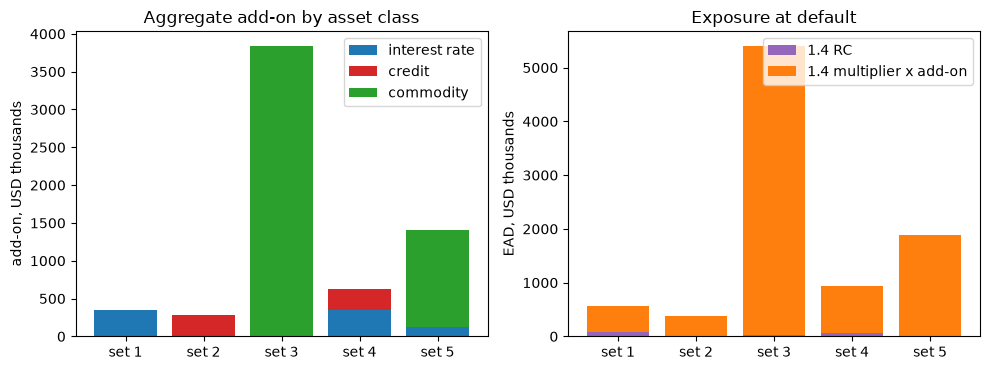

In [12]:
# Draw the add-on of each set by asset class (left) and its EAD as 1.4 RC plus 1.4 PFE (right)
parts = {1: (ir.addon, 0.0, 0.0), 2: (0.0, credit_terms.addon, 0.0), 3: (0.0, 0.0, commodity_total),
         4: (ir.addon, credit_terms.addon, 0.0), 5: (addon_ir5, 0.0, addon_com5)}
sets = list(result)
x = np.arange(len(sets))
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
bottom = np.zeros(len(sets))
classes = (("interest rate", 0, "tab:blue"), ("credit", 1, "tab:red"),
           ("commodity", 2, "tab:green"))
for label, j, color in classes:
    heights = np.array([parts[n][j] for n in sets])
    left.bar(x, heights, bottom=bottom, color=color, label=label)
    bottom += heights
left.set_xticks(x, [f"set {n}" for n in sets])
left.set_ylabel("add-on, USD thousands")
left.set_title("Aggregate add-on by asset class")
left.legend()
rc_part = np.array([1.4 * result[n].rc for n in sets])
pfe_part = np.array([1.4 * result[n].pfe for n in sets])
right.bar(x, rc_part, color="tab:purple", label="1.4 RC")
right.bar(x, pfe_part, bottom=rc_part, color="tab:orange", label="1.4 multiplier x add-on")
right.set_xticks(x, [f"set {n}" for n in sets])
right.set_ylabel("EAD, USD thousands")
right.set_title("Exposure at default")
right.legend()
fig.tight_layout()
plt.show()

Commodities dominate the picture: set 3 has an add-on of 3,841 against 347 for interest rates and 282 for credit, so its exposure at default is more than ten times that of sets 1 and 2. Sets 1 to 3 are almost all potential future exposure, since their replacement cost is small or zero, while set 5, with a large surplus of collateral, has a replacement cost of zero and its exposure is the add-on alone, reduced by the margined maturity factor. The figure shows the five official examples and nothing more; the sizes are the framework's illustration, not a typical bank book.

### Step 8: every intermediate against the printed value

The framework prints each intermediate rounded (to the nearest integer, or to three or four decimals). The test is that our unrounded number, rounded as the framework rounds it, is the printed one. The next cell does it for the five examples, for every output that appears in the `published` list, taking our value from the steps above.

In [13]:
# Compare each output with the printed value after the printed rounding, and the five EAD
FIELDS = ("rc", "addon_aggregate", "multiplier", "ead")
ours = {f"cre99-netting-set-{n}": {k: getattr(result[n], k) for k in FIELDS} for n in result}
hs1 = ir.hedging_sets
ours["cre99-netting-set-1"].update(addon_ir=ir.addon, swaption_delta=delta_put)
ours["cre99-netting-set-1"].update(en_usd=hs1[0].effective_notional, en_eur=hs1[1].effective_notional)
ours["cre99-netting-set-2"].update(term_1=credit_terms.systematic, term_2=credit_terms.idiosyncratic)
ours["cre99-netting-set-2"].update(addon_credit=credit_terms.addon)
energy = sa_ccr.commodity_addon({"energy": by_set["energy"]})
metals = sa_ccr.commodity_addon({"metals": by_set["metals"]})
ours["cre99-netting-set-3"].update(addon_commodity=commodity_total, addon_energy=energy, addon_metals=metals)
ours["cre99-netting-set-4"].update(addon_ir=ir.addon, addon_credit=credit_terms.addon)
ours["cre99-netting-set-5"].update(addon_ir=addon_ir5, addon_commodity=addon_com5, maturity_factor=mf5)

ROUNDING = {"nearest integer": 0, "3 decimal places": 3, "4 decimal places": 4}
checked = matched = 0
for ident, mine in ours.items():
    for p in examples[ident]["published"]:
        if p["name"] in mine:
            digits = ROUNDING.get(p["rounding"])
            shown = mine[p["name"]] if digits is None else round(mine[p["name"]], digits)
            matched += int(shown == p["value"])
            checked += 1
print("printed values checked:", checked, "| equal after the printed rounding:", matched)
print(f"{'set':>6s}{'EAD, ours':>16s}{'EAD, printed':>16s}")
for n in result:
    printed = {p["name"]: p["value"] for p in examples[f"cre99-netting-set-{n}"]["published"]}
    print(f"{n:6d}{result[n].ead:16.4f}{printed['ead']:16.0f}")

printed values checked: 34 | equal after the printed rounding: 34
   set       EAD, ours    EAD, printed
     1        569.4701             569
     2        381.2383             381
     3       5405.6160            5406
     4        936.4505             936
     5       1879.2126            1879


## Results

**Answer:** SA-CCR gives the five official netting sets an exposure at default of 569.47, 381.24, 5,405.62, 936.45 and 1,879.21 (USD thousands), which round to the 569, 381, 5,406, 936 and 1,879 the framework prints. The offset between maturity buckets removes 44.5% of the interest-rate add-on of set 1 (346.76 against 625.15 without it), the multiplier of set 2 is 0.9652 because its value is below zero, and the margin agreement of set 5 shrinks every maturity factor to 0.3550.

- **The parameters.** The table of CRE52.72 holds 43 rows, and each parameter comes with its paragraph, table and in-force date (2023-01-01), so a number on a screen can show where it comes from.
- **Interest rates (set 1).** The 10-year payer has duration 7.869 and effective notional +78,694; the 4-year receiver has duration 3.625 and falls in bucket B2 with -36,254; the EUR swaption has delta -0.2694, a bought put. The USD hedging set offsets the two buckets to an effective notional of 59,270 and an add-on of 296.35; with the EUR set the interest-rate add-on is 346.76.
- **Credit (set 2).** The systematic term is 2,252.6 and the idiosyncratic one 77,344.0; the add-on is 282.13.
- **Commodities (set 3).** The energy set gives 2,041.15 and the metals set 1,800.00; the class add-on is 3,841.15.
- **Aggregation (set 4).** Set 4 is sets 1 and 2 together. Its aggregate add-on, 628.89, is the sum 346.76 + 282.13, because add-ons add across asset classes, while its replacement cost, 40, nets the values 60 and -20. The EAD is 936.45.
- **Margin (set 5).** The MPoR is $10 + 5 - 1 = 14$ business days, the document's input. The replacement cost is $\max(-120, -145, 0) = 0$. The multiplier is 0.9581 and the EAD 1,879.21.
- **Against the framework.** Of the 34 printed intermediates, all 34 agree after the printed rounding.

What the engine does not implement of SA-CCR is stated in its documentation: the shift of strike and price for negative rates (CRE52.40), the vega of FX and commodity options, basis and volatility transactions, and the sign rules for FX trades beyond a signed effective notional the caller supplies. The five examples use only interest-rate, credit and commodity trades, so they do not exercise the FX and equity add-ons, which the engine offers as `fx_addon` and `equity_addon`.

## Summary

- $EAD = 1.4\,(RC + \text{multiplier} \times \text{AddOn})$; the add-on is the sum over five asset classes, each built from effective notionals $\delta \times N \times SD \times MF$.
- Interest-rate trades offset across three maturity buckets, credit and commodity trades across entities by a systematic plus idiosyncratic formula, and add-ons add across classes.
- A margin agreement changes three things: the MPoR $F + N - 1$, the maturity factor $1.5\sqrt{MPoR/250}$ and the replacement cost $\max(V - C, TH + MTA - NICA, 0)$.
- The five CRE99 examples are computed from their trades: 34 of 34 printed intermediates agree after the printed rounding.

**What to try next.** Remove the offset (`offset=False`) in set 5 and see how much the interest-rate add-on grows; change the swaption to a sold put and watch the EUR hedging set flip sign. Then continue with notebook 05.

## References

- BCBS, Basel Framework, CRE52 Standardised approach to counterparty credit risk (in force 2023-01-01, published 2020-06-05). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/52/inforce/2023-01-01/published/2020-06-05
- BCBS, Basel Framework, CRE99 Illustrative examples of the standardised approach to counterparty credit risk (in force 2023-01-01). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/99/inforce/2023-01-01/published/2020-03-27
- BCBS, Basel Framework, CRE53 Internal model method for counterparty credit risk (in force 2023-01-01, published 2020-06-05). https://www.bis.org/basel_framework/chapter/CRE/53.htm?inforce=20230101&published=20200605